# 02 - Selecao de Features

Seleciona as features de cada modelo do IDS em duas etapas:

- **Modelo 1 (binario):** BENIGN x Ataque
- **Modelo 2 (tipo de ataque):** DDoS, PortScan, WebAttack, SQLInjection

Ordem do processo:

1. Limpeza e remocao de duplicatas (`src/data.py`), incluindo as features removidas por decisao de dominio:
   colunas constantes, colunas identicas a outras e atalhos (`Destination Port`, `Init_Win_bytes_*`).
2. Divisao treino/teste estratificada. **O teste nao e usado neste notebook.**
3. Para cada modelo, no treino:
   - ranking inicial por importancia SHAP do XGBoost;
   - remocao de features muito correlacionadas (|r| > 0.95), mantendo a mais importante;
   - novo ranking e curva de F1 (validacao cruzada) x numero de features;
   - escolha do menor k cujo F1 fica a no maximo um desvio padrao do melhor.

## 1. Setup

In [1]:
import sys
sys.path.append('..')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

from src.data import build_dataset, train_test, split_xy, DROP_COLUMNS
from src.features import (make_model, sample_weights, shap_importance, gain_importance,
                          correlation_filter, stratified_sample, topk_curve, choose_k)
from src.pipeline import MODELS_DIR

In [2]:
def plot_ranking(shap_rank, gain_rank, titulo, n=20):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    shap_rank.head(n)[::-1].plot.barh(ax=axes[0], color='steelblue')
    axes[0].set_title(f'{titulo} - SHAP (media |valor|)')
    gain_rank.head(n)[::-1].plot.barh(ax=axes[1], color='gray')
    axes[1].set_title(f'{titulo} - Gain')
    plt.tight_layout()
    plt.show()


def plot_curve(curve, k, titulo, metrica):
    plt.figure(figsize=(9, 5))
    plt.errorbar(curve['k'], curve['f1'], yerr=curve['std'], marker='o', capsize=3)
    plt.axvline(k, color='red', linestyle='--', label=f'k escolhido = {k}')
    plt.title(f'{titulo} - {metrica} x numero de features')
    plt.xlabel('Numero de features (top-k do ranking)')
    plt.ylabel(metrica)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def ks_para(n_features):
    return [k for k in [2, 3, 5, 8, 10, 12, 15, 20, 25, 30] if k < n_features] + [n_features]

## 2. Dados

In [3]:
df = build_dataset()
train, test = train_test(df)
X, y_bin, y_type = split_xy(train)

print('Dataset limpo e sem duplicatas:', df.shape)
print('Colunas removidas por decisao de dominio:', len(DROP_COLUMNS))
print('Features candidatas:', X.shape[1])
print('\nTreino por tipo:')
print(train['attack_type'].value_counts())

Dataset limpo e sem duplicatas: (454138, 60)
Colunas removidas por decisao de dominio: 20
Features candidatas: 58

Treino por tipo:
attack_type
BENIGN          257770
DDoS            102398
WebAttack         1596
PortScan          1535
SQLInjection        11
Name: count, dtype: int64


## 3. Modelo 1 - BENIGN x Ataque

As classes estao razoavelmente equilibradas no treino, entao este modelo nao usa pesos por classe.

### 3.1 Ranking inicial (todas as features)

SHAP mede quanto cada feature muda a previsao, em media. O *gain* (importancia padrao do XGBoost)
aparece ao lado so para comparacao: ele costuma superestimar features usadas em poucas divisoes.

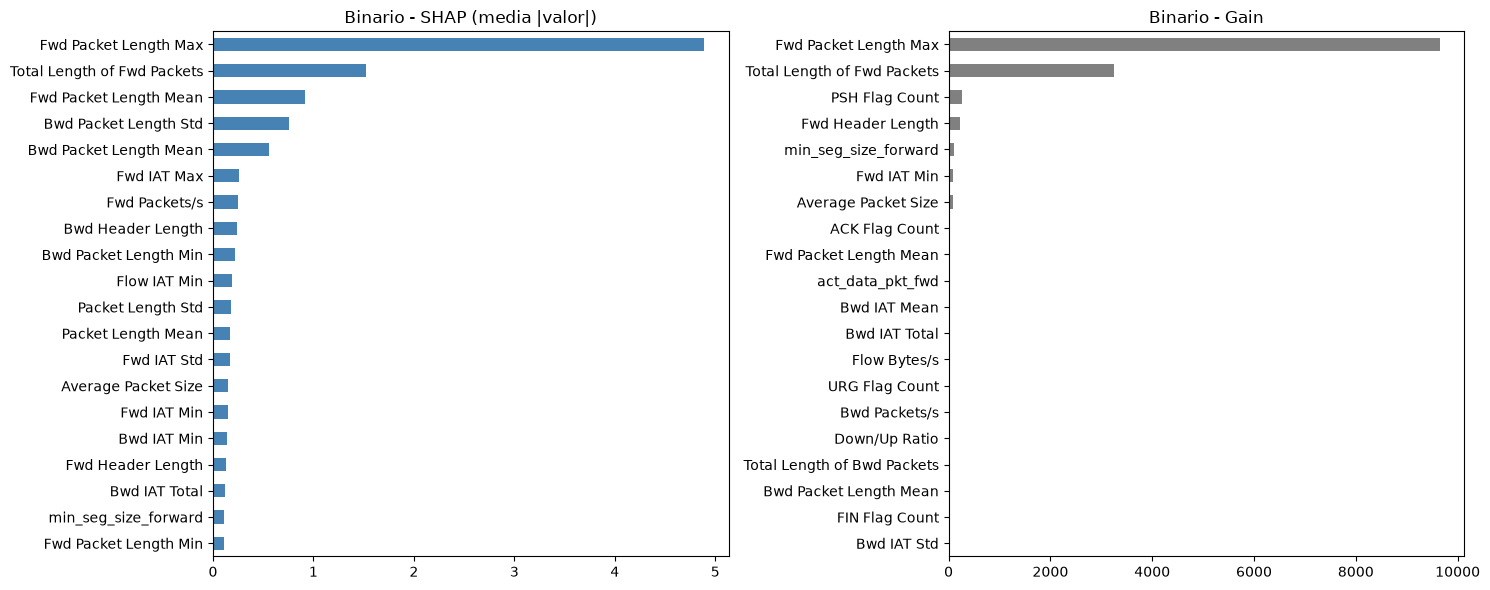

In [4]:
modelo = make_model(2)
modelo.fit(X, y_bin)

X_amostra_bin, _ = stratified_sample(X, y_bin, 5000)
rank_bin = shap_importance(modelo, X_amostra_bin)
plot_ranking(rank_bin, gain_importance(modelo, X.columns), 'Binario')

### 3.2 Remocao de features correlacionadas

In [5]:
kept_bin, dropped_bin = correlation_filter(X, rank_bin)
print(f'Mantidas: {len(kept_bin)} | Removidas: {len(dropped_bin)}')
pd.Series(dropped_bin, name='correlacionada com (mantida)').to_frame()

Mantidas: 40 | Removidas: 18


,correlacionada com (mantida)
Bwd Packet Length Mean,Bwd Packet Length Std
Packet Length Mean,Packet Length Std
Average Packet Size,Packet Length Std
Fwd Header Length,Bwd Header Length
Bwd Packet Length Max,Bwd Packet Length Std
act_data_pkt_fwd,Bwd Header Length
Fwd Packet Length Std,Fwd Packet Length Max
Total Fwd Packets,Bwd Header Length
Flow IAT Max,Fwd IAT Max
Total Length of Bwd Packets,Bwd Header Length


### 3.3 Ranking final e curva F1 x numero de features

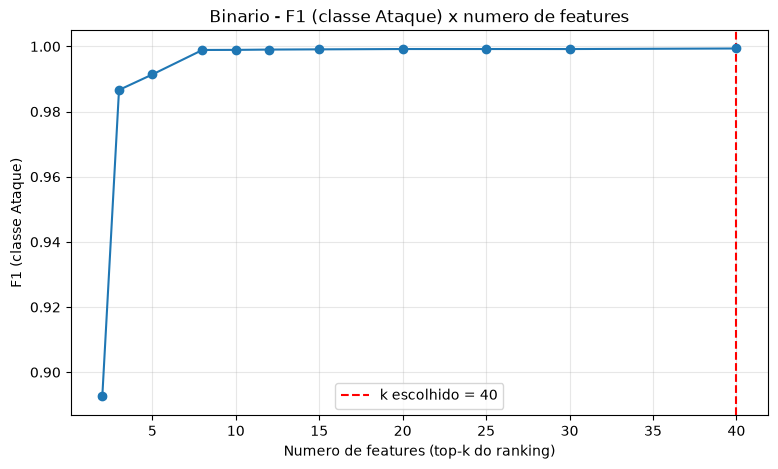

,k,f1,std
0,2,0.892673,0.000589
1,3,0.986635,0.000093
2,5,0.991393,0.000121
3,8,0.998910,0.000161
4,10,0.998938,0.000150
5,12,0.999033,0.000131
6,15,0.999100,0.000128
7,20,0.999199,0.000116
8,25,0.999199,0.000105
9,30,0.999195,0.000139


In [6]:
modelo = make_model(2)
modelo.fit(X[kept_bin], y_bin)
rank_bin = shap_importance(modelo, X_amostra_bin[kept_bin])

curve_bin = topk_curve(X, y_bin, rank_bin, ks_para(len(kept_bin)), balanced=False)
k_bin = choose_k(curve_bin)
features_bin = list(rank_bin.index[:k_bin])

plot_curve(curve_bin, k_bin, 'Binario', 'F1 (classe Ataque)')
curve_bin

In [7]:
print(f'{k_bin} features selecionadas para o modelo binario:')
rank_bin.head(k_bin).rename('SHAP').to_frame()

40 features selecionadas para o modelo binario:


,SHAP
Fwd Packet Length Max,4.379430
Fwd Packet Length Mean,1.489622
Total Length of Fwd Packets,1.468420
Bwd Packet Length Std,1.381543
Bwd Header Length,0.319909
Fwd IAT Max,0.286991
Fwd Packets/s,0.236106
Fwd IAT Min,0.213840
Bwd IAT Total,0.191663
Flow IAT Min,0.189447


## 4. Modelo 2 - Tipo de ataque

Treinado so com fluxos de ataque. Aqui o desequilibrio e extremo (DDoS tem dezenas de milhares
de linhas, SQLInjection tem 11 no treino), entao o modelo usa **pesos por classe** (`balanced`)
e a metrica e o **F1 macro**, que da o mesmo peso a todas as classes.

In [8]:
ataques = y_bin == 1
X_att = X[ataques]
le = LabelEncoder()
y_att = pd.Series(le.fit_transform(y_type[ataques]), index=X_att.index)

print('Classes:', list(le.classes_))
print(y_type[ataques].value_counts())

Classes: ['DDoS', 'PortScan', 'SQLInjection', 'WebAttack']
attack_type
DDoS            102398
WebAttack         1596
PortScan          1535
SQLInjection        11
Name: count, dtype: int64


### 4.1 Ranking inicial (todas as features)

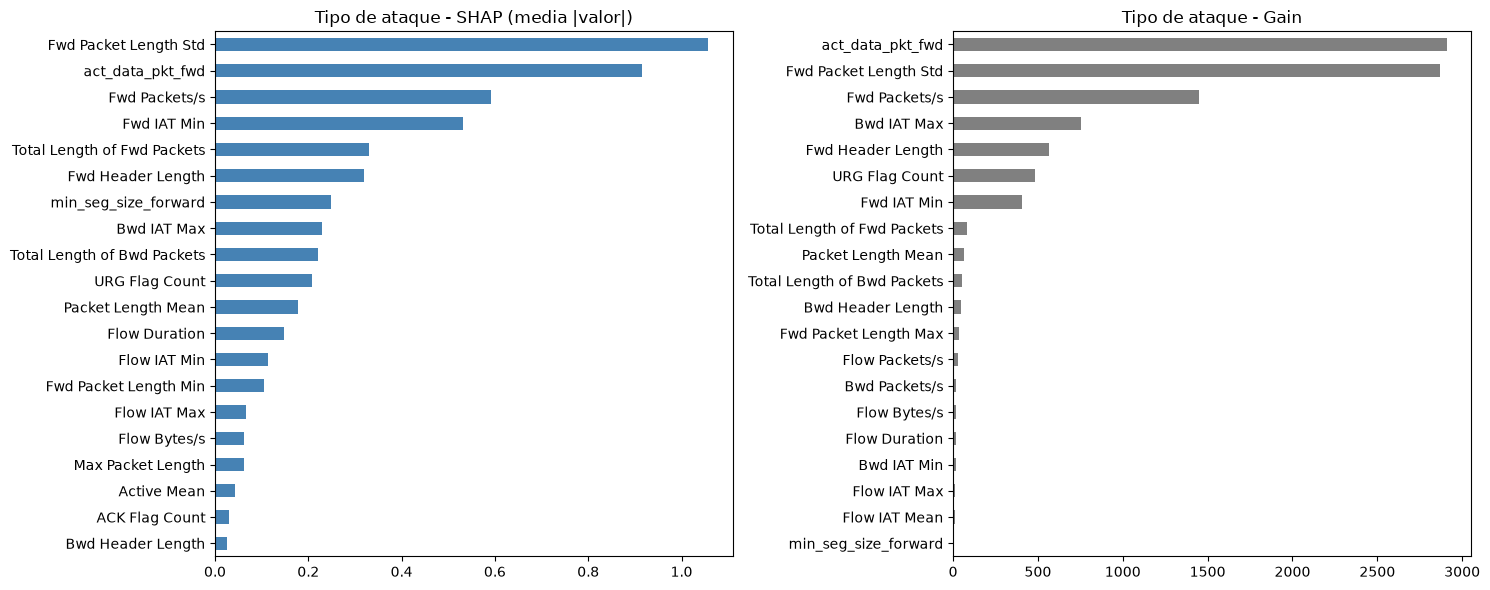

In [9]:
modelo = make_model(y_att.nunique())
modelo.fit(X_att, y_att, sample_weight=sample_weights(y_att, balanced=True))

X_amostra_att, _ = stratified_sample(X_att, y_att, 5000)
rank_att = shap_importance(modelo, X_amostra_att)
plot_ranking(rank_att, gain_importance(modelo, X_att.columns), 'Tipo de ataque')

### 4.2 Remocao de features correlacionadas

In [10]:
kept_att, dropped_att = correlation_filter(X_att, rank_att)
print(f'Mantidas: {len(kept_att)} | Removidas: {len(dropped_att)}')
pd.Series(dropped_att, name='correlacionada com (mantida)').to_frame()

Mantidas: 33 | Removidas: 25


,correlacionada com (mantida)
Fwd Header Length,Total Length of Fwd Packets
Bwd IAT Max,Fwd IAT Min
Flow IAT Max,Flow Duration
Flow IAT Std,Flow Duration
Fwd IAT Std,Flow Duration
Bwd IAT Min,Fwd IAT Min
Flow Packets/s,Fwd Packets/s
Total Backward Packets,Bwd Header Length
Fwd IAT Max,Flow Duration
Fwd IAT Total,Flow Duration


### 4.3 Ranking final e curva F1 macro x numero de features

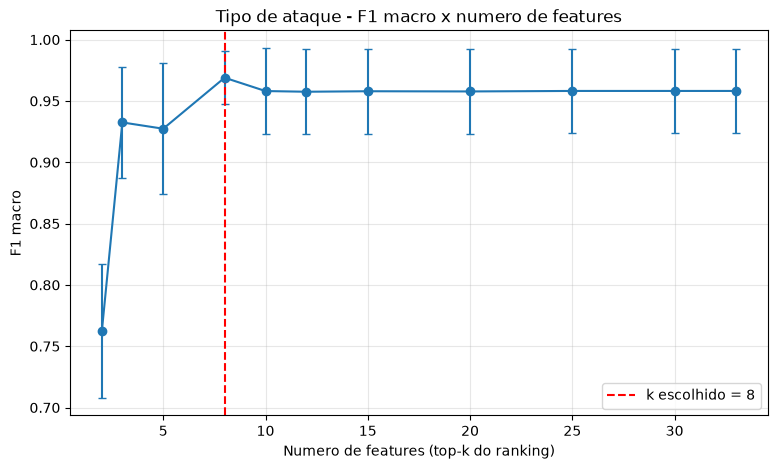

,k,f1,std
0,2,0.762470,0.054665
1,3,0.932494,0.045325
2,5,0.927364,0.053588
3,8,0.968949,0.021762
4,10,0.958081,0.035102
5,12,0.957519,0.034785
6,15,0.957920,0.034777
7,20,0.957762,0.034679
8,25,0.958163,0.034500
9,30,0.958163,0.034500


In [11]:
modelo = make_model(y_att.nunique())
modelo.fit(X_att[kept_att], y_att, sample_weight=sample_weights(y_att, balanced=True))
rank_att = shap_importance(modelo, X_amostra_att[kept_att])

curve_att = topk_curve(X_att, y_att, rank_att, ks_para(len(kept_att)), balanced=True)
k_att = choose_k(curve_att)
features_att = list(rank_att.index[:k_att])

plot_curve(curve_att, k_att, 'Tipo de ataque', 'F1 macro')
curve_att

In [12]:
print(f'{k_att} features selecionadas para o modelo de tipo de ataque:')
rank_att.head(k_att).rename('SHAP').to_frame()

8 features selecionadas para o modelo de tipo de ataque:


,SHAP
Fwd Packet Length Std,1.159189
act_data_pkt_fwd,0.900309
Fwd Packets/s,0.671861
Fwd IAT Min,0.576530
min_seg_size_forward,0.486924
Packet Length Mean,0.280164
Total Length of Fwd Packets,0.276469
Bwd IAT Total,0.241335


## 5. Salvar selecao

In [13]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
for nome, features, curve, k in [('binario', features_bin, curve_bin, k_bin),
                                 ('tipo_ataque', features_att, curve_att, k_att)]:
    linha = curve.set_index('k').loc[k]
    with open(MODELS_DIR / f'selecao_features_{nome}.json', 'w', encoding='utf-8') as f:
        json.dump({'features': features, 'f1_cv': round(float(linha['f1']), 6),
                   'f1_cv_std': round(float(linha['std']), 6)}, f, indent=2, ensure_ascii=False)

print('Em comum entre os dois modelos:', sorted(set(features_bin) & set(features_att)))

Em comum entre os dois modelos: ['Bwd IAT Total', 'Fwd IAT Min', 'Fwd Packets/s', 'Total Length of Fwd Packets', 'min_seg_size_forward']
